# ARTI-450: Project 1 - Multilayered Perceptrons
Dylan Dyke and Eddie Kaufuma-Henry

## Import Statements

In [2]:
# Data handling
import pandas as pd
import numpy as np

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Handling imbalanced data using SMOTE
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler

## Exploratory Data Analysis

In [3]:
df = pd.read_csv("loan_default.csv")

In [4]:
df.sample(10)

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
141130,8GVPIOGD60,36,137636,42216,430,106,3,11.15,12,0.82,PhD,Unemployed,Married,No,No,Auto,Yes,0
206802,FKNAYVRSLX,33,64075,113482,346,51,2,10.71,36,0.82,High School,Self-employed,Divorced,No,No,Education,No,0
184280,1XETJLHL6G,29,116289,69103,506,12,2,4.09,36,0.72,PhD,Unemployed,Divorced,Yes,No,Business,Yes,0
92263,T5TJIUW4X2,20,32621,14280,443,105,3,16.21,36,0.81,High School,Full-time,Single,Yes,Yes,Other,Yes,0
251880,ZYX9BH86M6,52,125031,89429,349,2,4,15.91,60,0.26,Master's,Unemployed,Married,Yes,No,Other,No,0
154057,HJCRTTHMK5,31,80183,152899,439,77,2,5.94,48,0.50,PhD,Full-time,Single,Yes,Yes,Business,Yes,0
132782,4GYWO1AQEM,37,53021,227015,805,63,1,2.84,48,0.44,PhD,Self-employed,Single,Yes,No,Home,No,0
26678,EY8EW9RN5A,67,20340,94692,707,87,4,3.31,48,0.33,Bachelor's,Unemployed,Married,Yes,Yes,Education,Yes,0
169870,RDLAKOMGEQ,38,90953,138458,344,45,3,9.86,36,0.36,Master's,Self-employed,Divorced,No,Yes,Home,No,0
206058,9S12JPJW1Q,32,145107,85643,479,110,1,21.52,12,0.88,Bachelor's,Self-employed,Married,Yes,Yes,Home,Yes,0


1. Dataset dimensions and feature types.
2. Descriptive statistics.
3. Missing-value analysis.
4. Duplicate-record analysis.
5. Target variable distribution.
6. Appropriate visualizations of important features.
7. Identification of potential outliers.

### Dataset dimensions and feature types.

In [5]:
#data dimensions & Feature Types
# Data dimensions: number of rows and columns
print("Data dimensions:")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Data type of each column
print("\nFeature types:")
print(df.dtypes)

Data dimensions:
Number of rows: 255347
Number of columns: 18

Feature types:
LoanID                str
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object


### Descriptive statistics.

In [6]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


### Missing Value Analysis

In [7]:
df.isnull().sum()

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

### Duplicate Record Analysis

In [8]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


### Target Variable Analysis

In [9]:
print(df["Default"].value_counts())
print("\nPercentage:")
print(df["Default"].value_counts(normalize=True) * 100)

Default
0    225694
1     29653
Name: count, dtype: int64

Percentage:
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


### Appropiate Visuals of Important Features

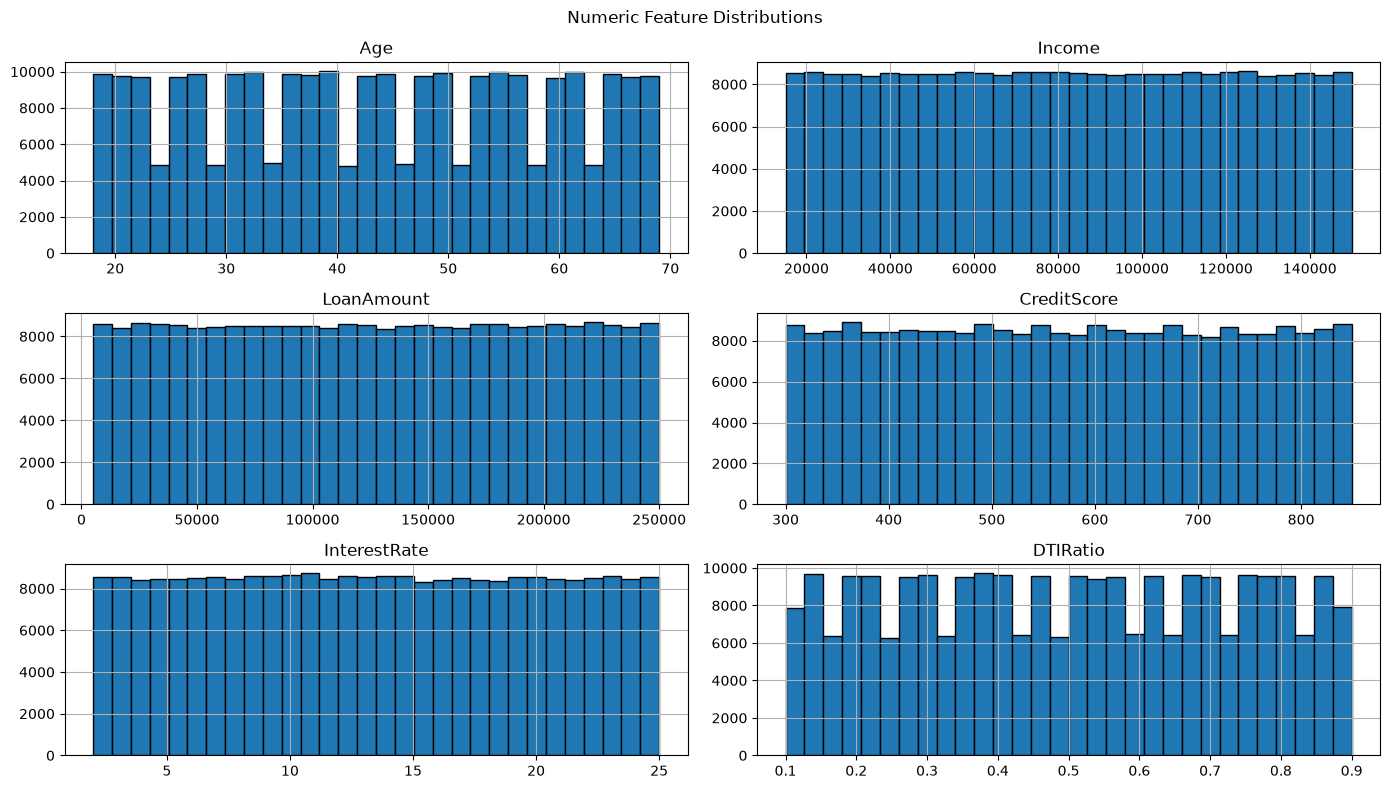

In [10]:
numeric_features = [
    "Age", "Income", "LoanAmount",
    "CreditScore", "InterestRate", "DTIRatio"
]

df[numeric_features].hist(
    figsize=(14, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.show()

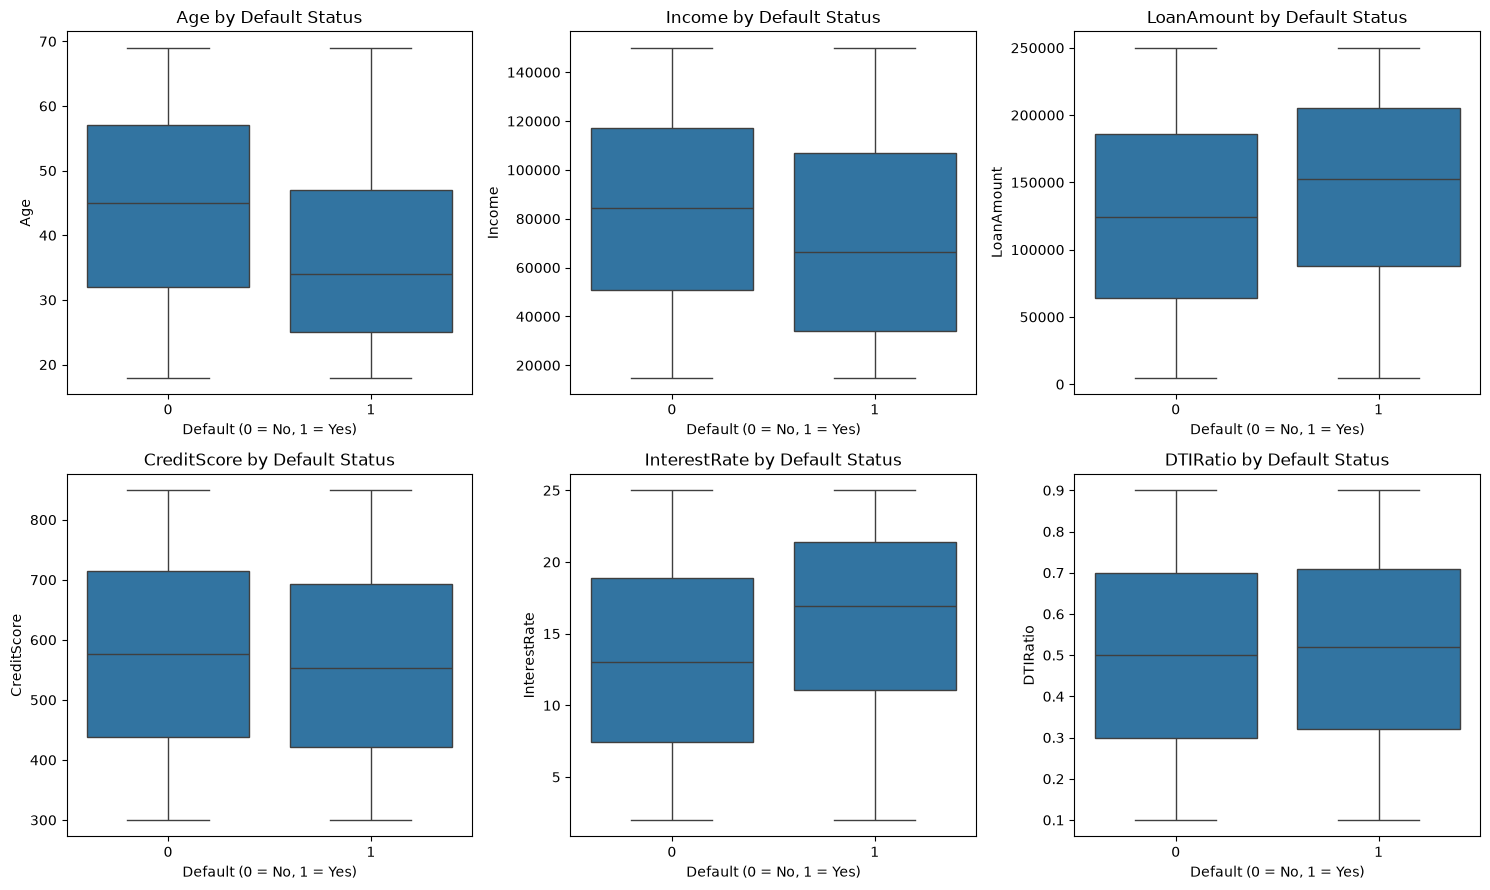

In [11]:
#Numeric features compared to target

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(numeric_features, axes.flatten()):
    sns.boxplot(data=df, x="Default", y=feature, ax=ax)
    ax.set_title(f"{feature} by Default Status")
    ax.set_xlabel("Default (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

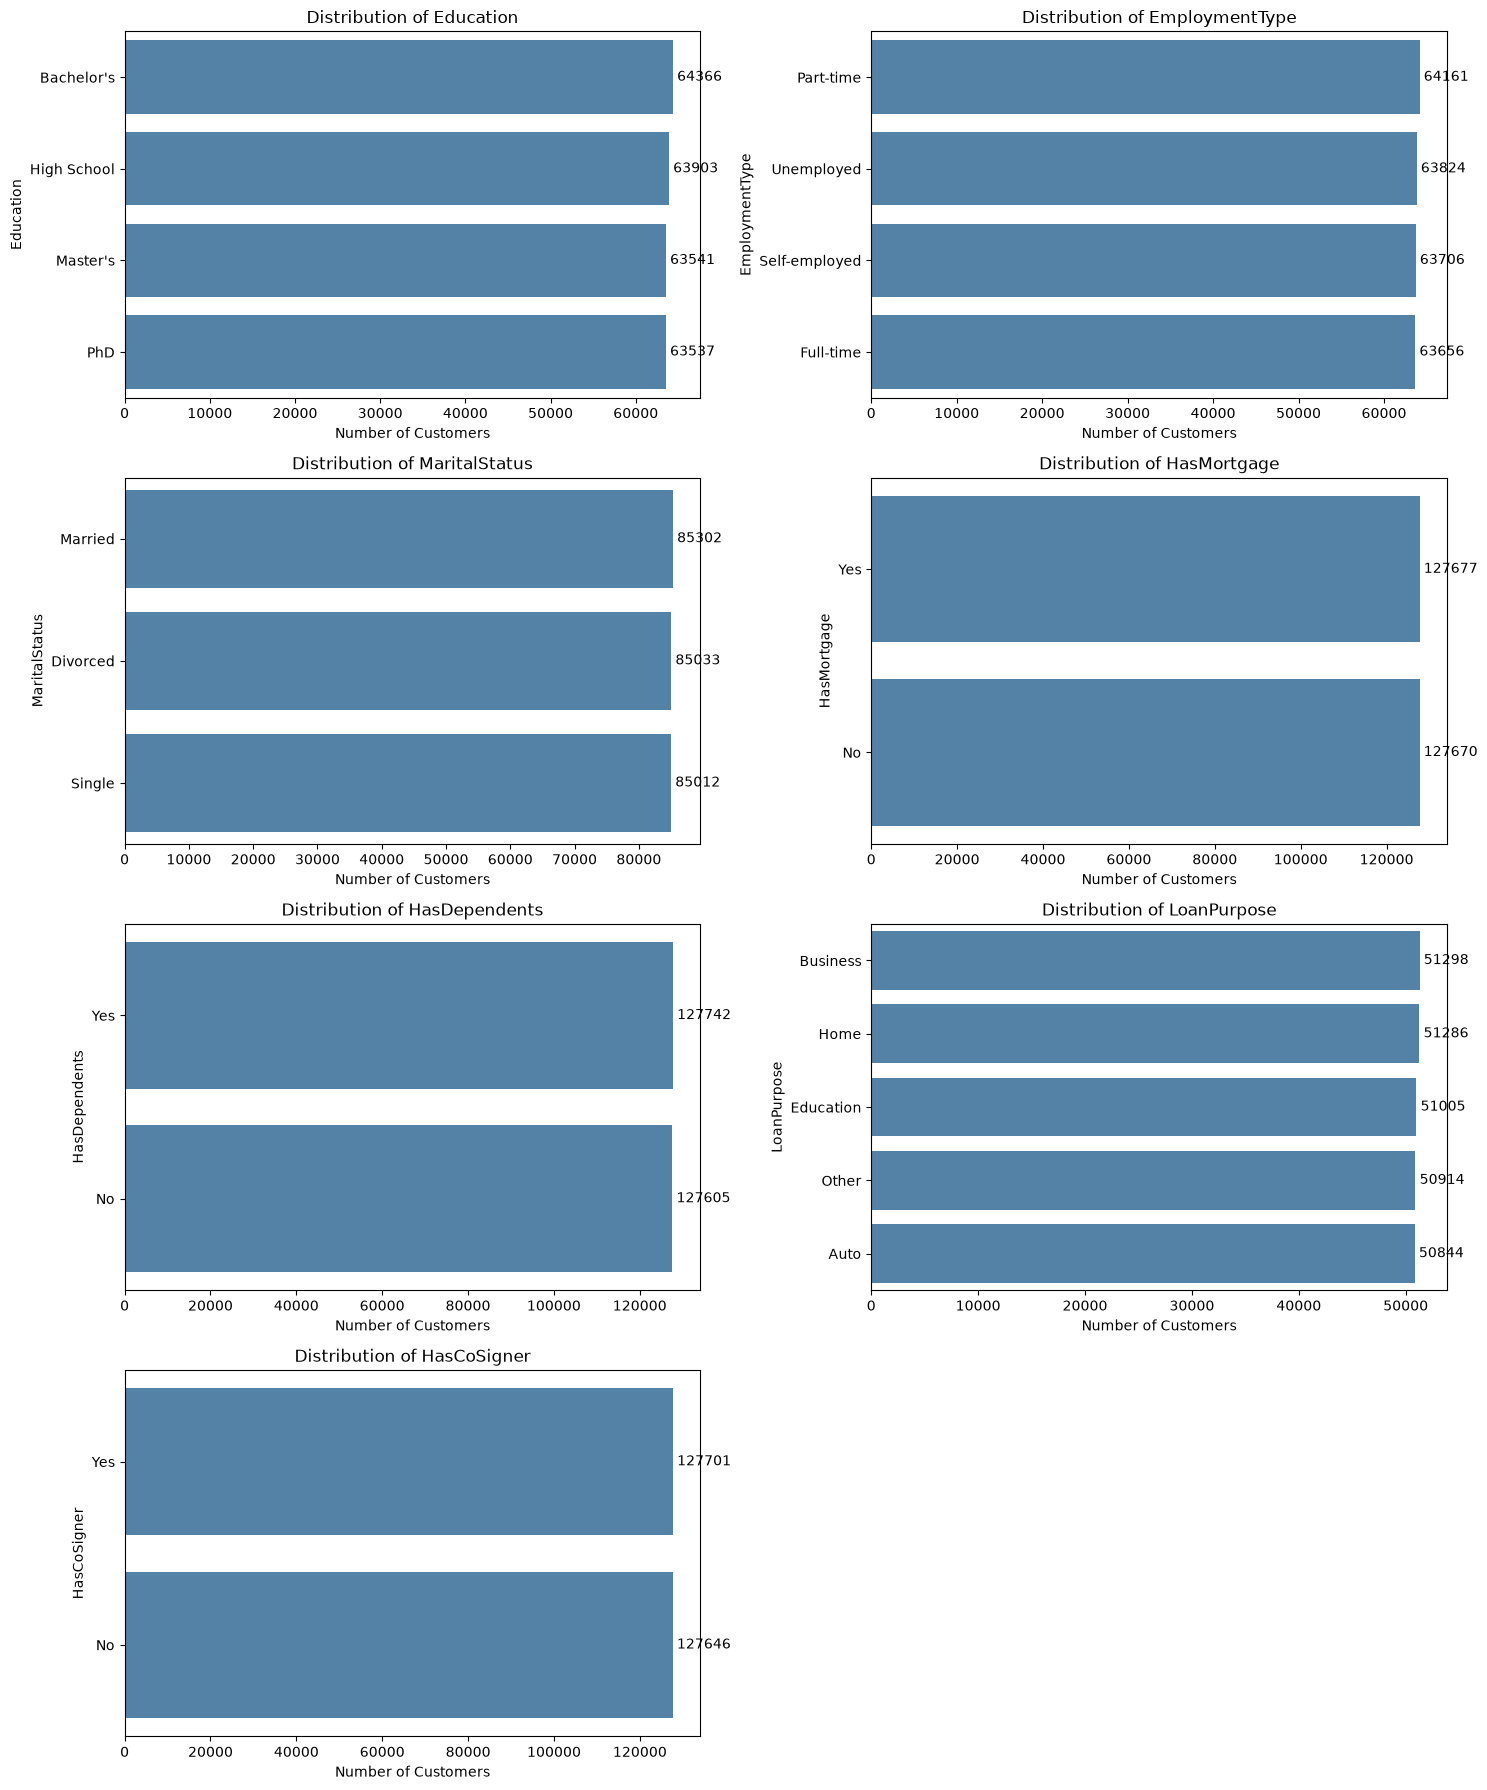

In [12]:
categorical_features = [
    "Education", "EmploymentType", "MaritalStatus",
    "HasMortgage", "HasDependents", "LoanPurpose", "HasCoSigner"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 18))

for feature, ax in zip(categorical_features, axes.flatten()):
    sns.countplot(
        data=df,
        y=feature,
        order=df[feature].value_counts().index,
        ax=ax,
        color="steelblue"
    )
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel("Number of Customers")
    ax.set_ylabel(feature)

# Hide the unused eighth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

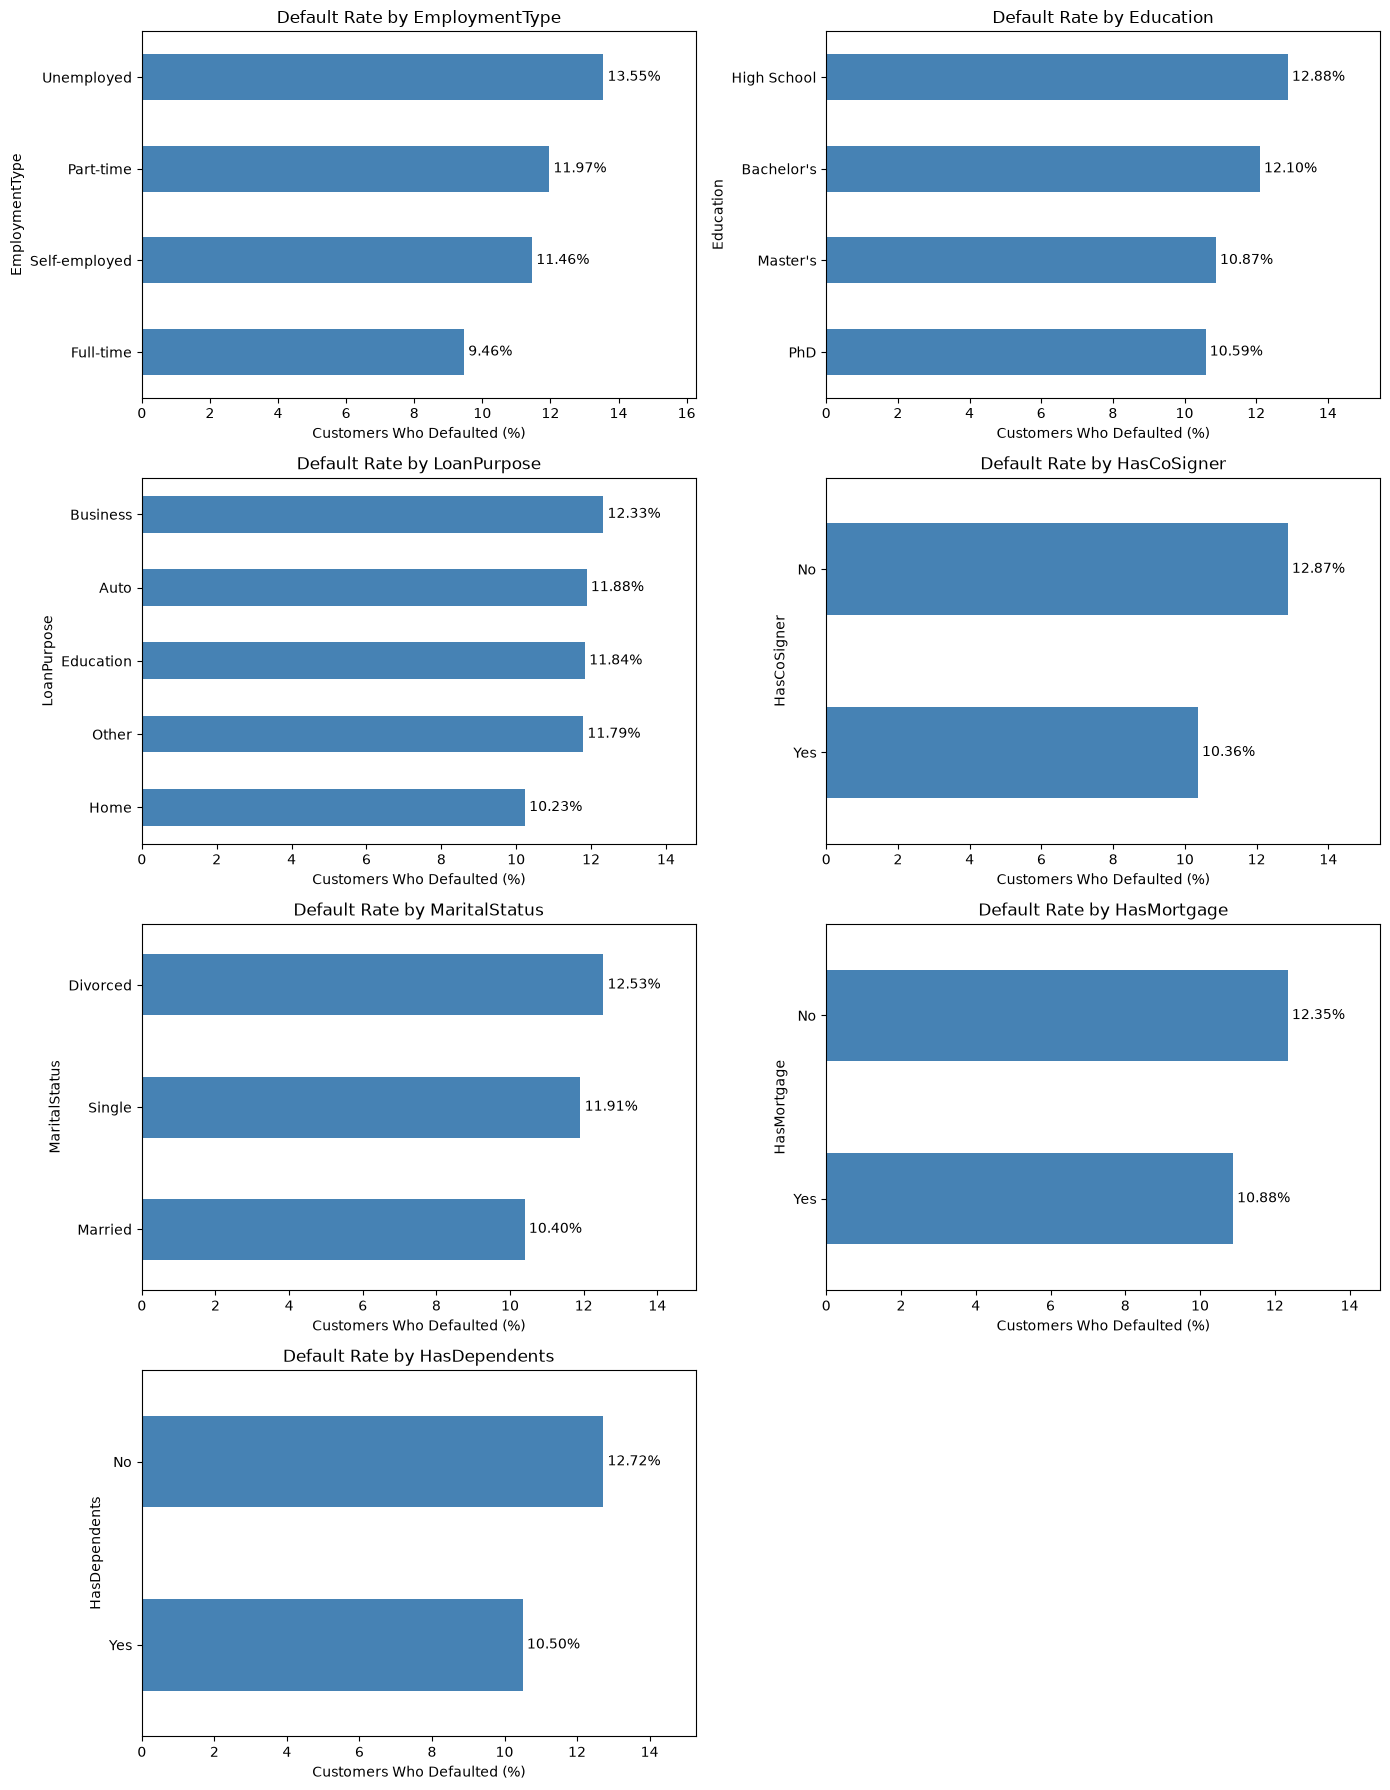

In [13]:
#categorical features compared to target
categorical_features = [
    "EmploymentType", "Education", "LoanPurpose", "HasCoSigner",
    "MaritalStatus", "HasMortgage", "HasDependents"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for feature, ax in zip(categorical_features, axes.flatten()):
    default_rates = (
        df.groupby(feature)["Default"]
        .mean()
        .mul(100)
        .sort_values()
    )

    default_rates.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"Default Rate by {feature}")
    ax.set_xlabel("Customers Who Defaulted (%)")
    ax.set_ylabel(feature)

    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    ax.set_xlim(0, default_rates.max() * 1.2)

# Hide the unused eighth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Identify Outliers

In [14]:
# Numeric features
numeric_features = df.select_dtypes(include="number").columns.drop("Default")

outlier_summary = []

for feature in numeric_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    )

    outlier_summary.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    })

# Display results
outlier_results = pd.DataFrame(outlier_summary)
outlier_results.round(2)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,-6.50,93.50,0,0.0
1,Income,-52264.75,217309.25,0,0.0
2,LoanAmount,-118087.50,373228.50,0,0.0
3,CreditScore,24.50,1124.50,0,0.0
4,MonthsEmployed,-60.00,180.00,0,0.0
5,NumCreditLines,0.50,4.50,0,0.0
6,InterestRate,-9.45,36.47,0,0.0
7,LoanTerm,-12.00,84.00,0,0.0
8,DTIRatio,-0.30,1.30,0,0.0


## Data Cleaning and Preprocessing

1. Handling missing values.
2. Removing duplicate observations where appropriate.
3. Addressing invalid or inconsistent data.
4. Encoding categorical variables.
5. Normalizing or standardizing numerical features.
6. Handling class imbalance, if applicable.
7. Splitting the dataset into training, validation, and testing sets.

In [15]:
# Separate features and target
X = df.drop(columns=["LoanID", "Default"]).copy()
y = df["Default"].copy()

# Map Yes/No to 1/0
binary_columns = ["HasMortgage", "HasDependents", "HasCoSigner"]

for column in binary_columns:
    X[column] = X[column].map({"No": 0, "Yes": 1})

### Splitting data

In [16]:
# Define column groups
numeric_columns = [
    "Age", "Income", "LoanAmount", "CreditScore",
    "MonthsEmployed", "NumCreditLines", "InterestRate",
    "LoanTerm", "DTIRatio"
]

categorical_columns = [
    "Education", "EmploymentType", "MaritalStatus", "LoanPurpose"
]

# SMOTENC must also recognize the binary columns as categorical
all_categorical_columns = categorical_columns + binary_columns

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

### Normalizing or standardizing numerical features

In [17]:
scaler = MinMaxScaler()

# Learn scaling from training data only
X_train[numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

# Apply the same scaling to validation and test data
X_val[numeric_columns] = scaler.transform(X_val[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

### Handle Class Imbalance.

In [18]:
print("Before SMOTENC:")
print(y_train.value_counts())

smote_nc = SMOTENC(
    categorical_features=all_categorical_columns,
    random_state=42
)

X_train_balanced, y_train_balanced = smote_nc.fit_resample(
    X_train, y_train
)

print("\nAfter SMOTENC:")
print(y_train_balanced.value_counts())

Before SMOTENC:
Default
0    157985
1     20757
Name: count, dtype: int64

After SMOTENC:
Default
0    157985
1    157985
Name: count, dtype: int64


### Encoding Categorical Values

In [19]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_columns])

encoded_names = encoder.get_feature_names_out(categorical_columns)

def encode_features(data):
    encoded = encoder.transform(data[categorical_columns])

    encoded_df = pd.DataFrame(
        encoded,
        columns=encoded_names,
        index=data.index
    )

    return pd.concat(
        [data.drop(columns=categorical_columns), encoded_df],
        axis=1
    )

X_train_balanced = encode_features(X_train_balanced)
X_train = encode_features(X_train)
X_val = encode_features(X_val)
X_test = encode_features(X_test)

print("Original training dimensions:", X_train.shape)
print("Balanced training dimensions:", X_train_balanced.shape)
print("Validation dimensions:", X_val.shape)
print("Test dimensions:", X_test.shape)

X_train_balanced.head()

Original training dimensions: (178742, 28)
Balanced training dimensions: (315970, 28)
Validation dimensions: (38302, 28)
Test dimensions: (38303, 28)


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,HasMortgage,...,EmploymentType_Self-employed,EmploymentType_Unemployed,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,LoanPurpose_Auto,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other
0,0.058824,0.976741,0.596443,0.981785,0.882353,0.333333,0.594348,0.25,0.7250,0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.352941,0.775828,0.261524,0.032787,0.773109,0.000000,0.025217,0.75,0.8625,0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.607843,0.820176,0.986106,0.901639,0.361345,1.000000,0.736522,0.00,0.9125,0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.333333,0.724287,0.731791,0.877960,0.067227,1.000000,0.277826,0.25,0.3250,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.627451,0.393670,0.387495,0.083789,0.974790,0.333333,0.657391,1.00,0.5125,1,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


## Feature Selection

- Identify the selected features: Age, Income, Loan Amount, Interestrate, CreditScore, EnrollmentType, HasCoSigner, Education, and HasDependents  
- Explain the feature selection technique: We manually engineered these features based on EDA using graphs comparing them with loan default and chose features that may help explain a customer’s ability to repay. This approach uses our understanding of the data.
-  Justify why the selected features are relevant:  Income, LoanAmount, and DTIRatio describe a customer’s financial situation and debt burden. CreditScore provides information about credit history. EmploymentType and MonthsEmployed describe employment status and income stability. InterestRate affects borrowing costs, while HasCoSigner shows whether another person shares responsibility for repayment (better odds of non-default). Age may also capture differences between borrowers. These features may help predict default, but comparing model results will help determine whether this smaller selection improves performance.
- Compare model performance using all eligible features versus the selected features

## MLP Development

Students must develop an MLP neural network using TensorFlow/Keras.

The MLP must include:
• An input layer.
• At least two hidden layers.
• Appropriate activation functions.
• An output layer suitable for the selected task.
• An appropriate loss function.
• An optimizer.
• Clearly defined training procedure.

Students must document:

1. Number of input features.
2. Number of hidden layers.
3. Number of neurons in each hidden layer.
4. Activation functions.
5. Loss function.
6. Optimizer and learning rate.
7. Batch size.
8. Number of training epochs

## Traditional Machine Learning Models

Students must implement at least two traditional machine learning models for comparison with the MLP.
Possible algorithms include:

• Logistic Regression or Linear Regression, depending on the task.
• Decision Tree.
• Random Forest.
• Support Vector Machine (SVM).
• K-Nearest Neighbors (KNN)

## Model Evaluation and Comparison

• Accuracy.
• Precision.
• Recall.
• F1-score.
• Confusion matrix.

Students must present a comparison table showing the performance of all models on the same
held-out test set.

The analysis should address:
1. Which model performed best?
2. Did feature selection improve model performance?
3. Did the MLP outperform traditional machine learning models?